In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [52]:
import pandas as pd

pd.set_option('display.max_columns', None)

df = pd.read_csv(
    "/content/drive/MyDrive/Healthcare data/kidney_waitlist_analytic.csv.gz",
    low_memory=False
)

manifest = pd.read_csv(
    "/content/drive/MyDrive/Healthcare data/column_manifest.csv"
)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde
from scipy.signal import find_peaks
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold
import os
import json

In [ ]:
df.head()

,ON_DIALYSIS,A2A2B_ELIGIBILITY,GENDER,ABO,BMI_TCR,FUNC_STAT_TCR,INIT_STAT,INIT_CPRA,END_CPRA,REM_CD,DAYSWAIT_CHRON,END_STAT,INIT_AGE,DIALYSIS_DATE,END_DATE,INIT_DATE,ETHCAT,PT_CODE,DAYSWAIT_ALLOC,COMPOSITE_DEATH_DATE,REGION,WL_ID_CODE,PREV_TX,TX_DATE,DON_TY,DIAG_KI,MULTIORG,ORGAN,PSTATUS,PTIME,TRR_ID_CODE,DONOR_ID,LISTING_CTR_CODE,outcome,event_adverse,event_transplant,censored,days_to_event
0,Y,NaN,F,B,31.63,2080.0,4099,0.0,0.0,8.0,287.0,4099,53,2018-03-30,2021-01-06,2020-03-25,2,1343681,1013.0,2021-01-06,8,1526706,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13609,died,1,0,0,287.0
1,Y,NaN,M,A,30.04,2070.0,4099,0.0,NaN,24.0,2322.0,4099,56,2017-08-16,2026-06-24,2020-02-14,1,1337977,3234.0,NaN,5,1519605,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6975,removed_administrative,0,0,0,2322.0
2,N,NaN,F,O,32.85,2070.0,4099,0.0,0.0,8.0,604.0,4099,47,NaN,2022-01-21,2020-05-27,1,1350622,604.0,2022-01-21,11,1535094,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19716,died,1,0,0,604.0
3,Y,NaN,M,A,20.00,2090.0,4099,0.0,0.0,13.0,909.0,4099,61,2019-01-05,2022-09-28,2020-04-02,5,1344761,1362.0,2025-02-08,7,1527782,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8587,removed_too_sick,1,0,0,909.0
4,Y,NaN,M,AB,23.30,2070.0,4010,0.0,0.0,13.0,231.0,4099,61,2019-01-10,2020-09-23,2020-02-05,2,1288889,622.0,2021-03-01,7,1517273,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18352,removed_too_sick,1,0,0,231.0


In [ ]:
shape = df.shape
shape

(494862, 38)

In [ ]:
columns = df.columns.to_list()
columns

['ON_DIALYSIS',
 'A2A2B_ELIGIBILITY',
 'GENDER',
 'ABO',
 'BMI_TCR',
 'FUNC_STAT_TCR',
 'INIT_STAT',
 'INIT_CPRA',
 'END_CPRA',
 'REM_CD',
 'DAYSWAIT_CHRON',
 'END_STAT',
 'INIT_AGE',
 'DIALYSIS_DATE',
 'END_DATE',
 'INIT_DATE',
 'ETHCAT',
 'PT_CODE',
 'DAYSWAIT_ALLOC',
 'COMPOSITE_DEATH_DATE',
 'REGION',
 'WL_ID_CODE',
 'PREV_TX',
 'TX_DATE',
 'DON_TY',
 'DIAG_KI',
 'MULTIORG',
 'ORGAN',
 'PSTATUS',
 'PTIME',
 'TRR_ID_CODE',
 'DONOR_ID',
 'LISTING_CTR_CODE',
 'outcome',
 'event_adverse',
 'event_transplant',
 'censored',
 'days_to_event']

In [ ]:
predict_classes = (df['outcome'].unique()).tolist()
predict_classes

['died',
 'removed_administrative',
 'removed_too_sick',
 'still_waiting',
 'transplanted_elsewhere',
 'unknown',
 'transplanted']

In [ ]:
null_check = df.isnull().sum()
has_missing = [column for column in null_check.index if null_check[column] > 0]
for column in has_missing:
  print(f'{column} : {null_check[column]}')



A2A2B_ELIGIBILITY : 456604
BMI_TCR : 1558
FUNC_STAT_TCR : 3975
INIT_CPRA : 142741
END_CPRA : 142448
REM_CD : 103300
DAYSWAIT_CHRON : 53
DIALYSIS_DATE : 134245
DAYSWAIT_ALLOC : 6745
COMPOSITE_DEATH_DATE : 398512
PREV_TX : 264107
TX_DATE : 264107
DON_TY : 264107
DIAG_KI : 265540
MULTIORG : 483004
ORGAN : 264107
PSTATUS : 264107
PTIME : 267350
TRR_ID_CODE : 264107
DONOR_ID : 264107
days_to_event : 59


In [ ]:
cat_cols = list((df.select_dtypes('object')).columns)
num_cols = list((df.select_dtypes(include = ['int64', 'float64'])).columns)

#Safety check
[print (column, df[column].dtype) for column in columns if column not in num_cols and column not in cat_cols ]

[]

In [ ]:
unique_cat_cols = {column : (df[column].nunique()) for column in cat_cols}
print(unique_cat_cols)


{'ON_DIALYSIS': 2, 'GENDER': 2, 'ABO': 8, 'DIALYSIS_DATE': 8953, 'END_DATE': 4196, 'INIT_DATE': 3805, 'COMPOSITE_DEATH_DATE': 4101, 'PREV_TX': 2, 'TX_DATE': 4189, 'DON_TY': 3, 'MULTIORG': 1, 'ORGAN': 2, 'TRR_ID_CODE': 230755, 'outcome': 7}


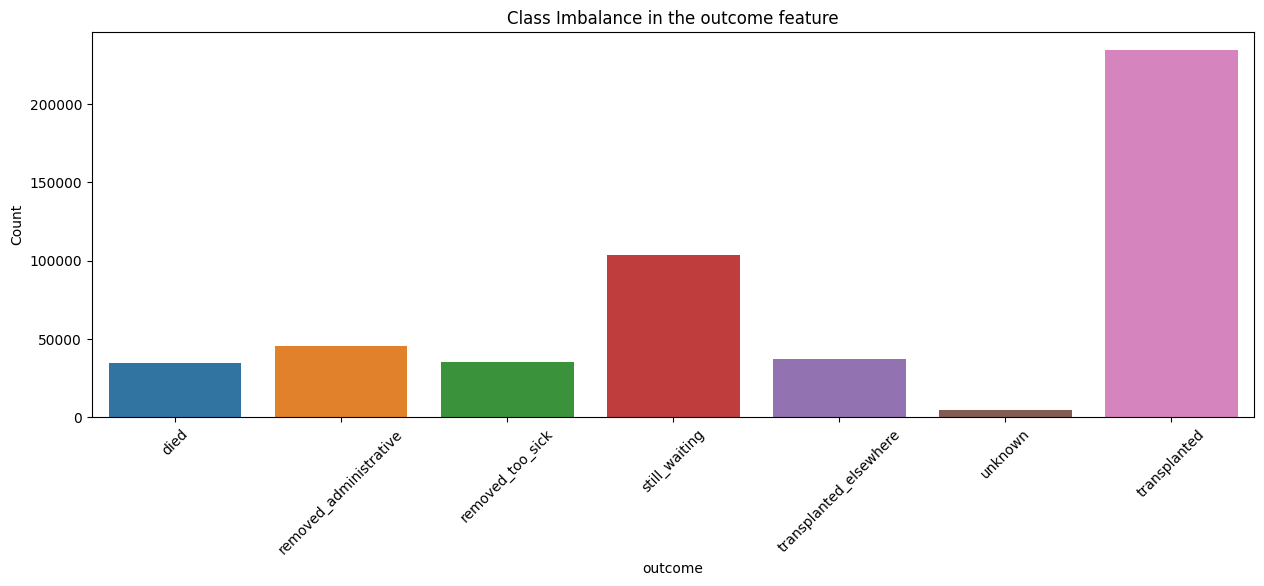

In [ ]:
fig = plt.figure(figsize=(15,5))
ax = sns.countplot(x = df["outcome"], hue =df['outcome'])
plt.title(f'Class Imbalance in the {df["outcome"].name} feature')
plt.xlabel(f'{df["outcome"].name}')
plt.ylabel('Count')
plt.xticks(rotation = 45)
plt.show()

In [ ]:
#Checking for the outliers in the numerical columns
q1 = df[num_cols].quantile(0.25)
q3 = df[num_cols].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

iqr_bool = (df[num_cols] < lower_bound)| (df[num_cols] > upper_bound)

outliers = iqr_bool.any()
outliers = [column for column in outliers.index if outliers[column] == True]
outliers

['BMI_TCR',
 'FUNC_STAT_TCR',
 'INIT_CPRA',
 'REM_CD',
 'DAYSWAIT_CHRON',
 'INIT_AGE',
 'ETHCAT',
 'PT_CODE',
 'DAYSWAIT_ALLOC',
 'WL_ID_CODE',
 'DIAG_KI',
 'PSTATUS',
 'PTIME',
 'event_adverse',
 'censored',
 'days_to_event']

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 494862 entries, 0 to 494861
Data columns (total 38 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   ON_DIALYSIS           494862 non-null  object 
 1   A2A2B_ELIGIBILITY     38258 non-null   float64
 2   GENDER                494862 non-null  object 
 3   ABO                   494862 non-null  object 
 4   BMI_TCR               493304 non-null  float64
 5   FUNC_STAT_TCR         490887 non-null  float64
 6   INIT_STAT             494862 non-null  int64  
 7   INIT_CPRA             352121 non-null  float64
 8   END_CPRA              352414 non-null  float64
 9   REM_CD                391562 non-null  float64
 10  DAYSWAIT_CHRON        494809 non-null  float64
 11  END_STAT              494862 non-null  int64  
 12  INIT_AGE              494862 non-null  int64  
 13  DIALYSIS_DATE         360617 non-null  object 
 14  END_DATE              494862 non-null  object 
 15  

In [ ]:
df.describe()

,A2A2B_ELIGIBILITY,BMI_TCR,FUNC_STAT_TCR,INIT_STAT,INIT_CPRA,END_CPRA,REM_CD,DAYSWAIT_CHRON,END_STAT,INIT_AGE,ETHCAT,PT_CODE,DAYSWAIT_ALLOC,REGION,WL_ID_CODE,DIAG_KI,PSTATUS,PTIME,DONOR_ID,LISTING_CTR_CODE,event_adverse,event_transplant,censored,days_to_event
count,38258.000000,493304.000000,490887.000000,494862.000000,352121.000000,352414.000000,391562.000000,494809.000000,494862.000000,494862.000000,494862.000000,4.948620e+05,488117.000000,494862.000000,4.948620e+05,229322.000000,230755.000000,227512.000000,230755.000000,494862.000000,494862.000000,494862.000000,494862.000000,494803.000000
mean,0.282242,64.700077,2106.332755,4036.217733,9.786130,29.219320,9.150027,649.532775,4038.288725,51.874533,5.907538,1.295265e+06,1303.998160,5.756225,1.595489e+06,2890.667337,0.119083,1241.054252,629284.062920,13040.187040,0.140934,0.473726,0.208745,649.541492
std,0.450096,3141.118209,343.735143,40.559675,24.799939,36.408157,5.932887,654.238307,41.437826,14.601018,59.611413,3.245015e+05,1068.064599,3.125680,2.306050e+05,534.282179,0.323887,947.761267,79431.124919,7742.892814,0.347954,0.499310,0.406412,654.237636
min,0.000000,0.180000,1.000000,4010.000000,0.000000,0.000000,4.000000,0.000000,4010.000000,0.000000,1.000000,2.200000e+01,0.000000,1.000000,1.835720e+05,999.000000,0.000000,0.000000,415814.000000,124.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,24.650000,2070.000000,4010.000000,0.000000,0.000000,4.000000,144.000000,4010.000000,43.000000,1.000000,1.153188e+06,501.000000,3.000000,1.397019e+06,3008.000000,0.000000,379.000000,565175.500000,6293.000000,0.000000,0.000000,0.000000,144.000000
50%,0.000000,28.530000,2080.000000,4010.000000,0.000000,6.860000,8.000000,433.000000,4010.000000,54.000000,2.000000,1.340636e+06,1083.000000,5.000000,1.597336e+06,3040.000000,0.000000,1087.000000,630483.000000,13454.000000,0.000000,0.000000,0.000000,433.000000
75%,1.000000,32.850000,2090.000000,4099.000000,0.000000,56.930000,14.000000,965.000000,4099.000000,63.000000,4.000000,1.527921e+06,1844.000000,9.000000,1.795160e+06,3070.000000,0.000000,1840.000000,696537.500000,19964.000000,0.000000,1.000000,0.000000,965.000000
max,1.000000,430226.670000,4100.000000,4099.000000,100.000000,100.000000,45.000000,4200.000000,4099.000000,91.000000,998.000000,1.730508e+06,15395.000000,11.000000,1.993444e+06,3074.000000,1.000000,4131.000000,767775.000000,27149.000000,1.000000,1.000000,1.000000,4200.000000


After we have decided on columns/features to exclude -->

Description of issues in the dataset:
  1. Non-integer values - From the ML foundations course, we have to use one-hot encoding technique to ensure all the features we plan to use have numerical values
  2. Null/Empty values - For numerical ones, we can just average the other data in the column to use it for the missing one. For objects, I believe we used the value that occurred most in the dataset for that column.
  3. Normalization - To ensure the ML model does not become biased or affected due to high values for certain numerical features, we should consider normalizing those features (converting the values into 0-1 range)
  4.

Baseline:
ON_DIALYSIS, A2A2B_ELIGIBILITY, ABO, BMI_TCR, FUNC_STAT_TCR, INIT_STAT, INIT_CPRA, INIT_AGE, DIALYSIS_DATE, INIT_DATE

Sensitive:
GENDER, ETHCAT, REGION

Identifier:
PT_CODE, WL_ID_CODE

Identifier / sensitive:
LISTING_CTR_CODE

Outcome:
END_CPRA, REM_CD, DAYSWAIT_CHRON, END_STAT, END_DATE, DAYSWAIT_ALLOC, COMPOSITE_DEATH_DATE, TX_DATE, DON_TY, MULTIORG, ORGAN, PSTATUS, PTIME, outcome, event_adverse, event_transplant, censored, days_to_event

Outcome in this extract:
PREV_TX, DIAG_KI

Identifier / outcome:
TRR_ID_CODE, DONOR_ID


In [ ]:
date_cols = [
    "INIT_DATE",
    "END_DATE",
    "DIALYSIS_DATE",
    "TX_DATE",
    "COMPOSITE_DEATH_DATE"
]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

date_quality = pd.Series({
    "missing_INIT_DATE": df["INIT_DATE"].isna().sum(),
    "END_DATE_before_INIT_DATE":
        (df["END_DATE"] < df["INIT_DATE"]).sum(),
    "TX_DATE_before_INIT_DATE":
        (df["TX_DATE"] < df["INIT_DATE"]).sum(),
    "death_date_before_INIT_DATE":
        (df["COMPOSITE_DEATH_DATE"] < df["INIT_DATE"]).sum(),
    "missing_days_to_event": df["days_to_event"].isna().sum(),
    "zero_day_events": df["days_to_event"].eq(0).sum()
})

display(date_quality.to_frame("count"))

,count
missing_INIT_DATE,0
END_DATE_before_INIT_DATE,59
TX_DATE_before_INIT_DATE,0
death_date_before_INIT_DATE,58
missing_days_to_event,59
zero_day_events,790


In [ ]:
invalid_date_mask = df["END_DATE"] < df["INIT_DATE"]

print("Invalid END_DATE records:", invalid_date_mask.sum())

print(
    "Invalid END_DATE records with missing days_to_event:",
    df.loc[invalid_date_mask, "days_to_event"].isna().sum()
)

Invalid END_DATE records: 59
Invalid END_DATE records with missing days_to_event: 59


In [ ]:
df_clean = df.loc[~invalid_date_mask].copy()

print("Original number of records:", len(df))
print("Invalid records excluded:", invalid_date_mask.sum())
print("Remaining records:", len(df_clean))

Original number of records: 494862
Invalid records excluded: 59
Remaining records: 494803


In [ ]:
zero_day_events = df_clean[df_clean["days_to_event"] == 0]

print("Total zero-day events:", len(zero_day_events))
print("\nZero-day events by outcome:")
print(zero_day_events["outcome"].value_counts())

Total zero-day events: 790

Zero-day events by outcome:
outcome
removed_administrative    396
transplanted              260
removed_too_sick           67
unknown                    44
died                       18
transplanted_elsewhere      5
Name: count, dtype: int64


In [ ]:
print(
    "Zero-day records where END_DATE equals INIT_DATE:",
    (zero_day_events["END_DATE"] == zero_day_events["INIT_DATE"]).sum()
)

print(
    "Zero-day records where END_DATE does NOT equal INIT_DATE:",
    (zero_day_events["END_DATE"] != zero_day_events["INIT_DATE"]).sum()
)

Zero-day records where END_DATE equals INIT_DATE: 790
Zero-day records where END_DATE does NOT equal INIT_DATE: 0


Date Validation Findings — Issue #13

The date columns were converted to pandas datetime format using pd.to_datetime() with errors="coerce" to allow date comparisons and safely represent invalid or missing dates as NaT.

Date validation identified 59 records where END_DATE occurred before INIT_DATE. All 59 of these records also had missing days_to_event, confirming that they are invalid for time-to-event analysis. These records were excluded from the cleaned dataset, reducing the dataset from 494,862 to 494,803 records.

There were also 790 records with days_to_event == 0. Investigation showed that all 790 had END_DATE == INIT_DATE, indicating internally consistent same-day outcomes. The zero-day observations included multiple outcome categories rather than a single anomalous category. Therefore, zero-day events are retained during data cleaning rather than treated as data errors. If a later survival-analysis method requires strictly positive durations, these observations should be handled according to that model's requirements.

In [ ]:
HORIZON_DAYS = 365

# Positive: died or removed as too sick within 365 days
positive_365 = (
    df["event_adverse"].eq(1)
    & df["days_to_event"].le(HORIZON_DAYS)
)

# Negative: observed for at least 365 days without an early adverse event
observed_one_year = df["days_to_event"].ge(HORIZON_DAYS)

# A transplant before 365 days is a definitive competing outcome
early_transplant = (
    df["outcome"].isin(["transplanted", "transplanted_elsewhere"])
    & df["days_to_event"].le(HORIZON_DAYS)
)

eligible_for_model = (
    (positive_365 | observed_one_year | early_transplant)
    & df["days_to_event"].notna()
    & df["outcome"].ne("unknown")
)

model_df = df.loc[eligible_for_model].copy()

model_df["adverse_365"] = (
    positive_365.loc[model_df.index]
    .astype(int)
)

print("Modeling rows:", len(model_df))
print(model_df["adverse_365"].value_counts())
print(model_df["adverse_365"].value_counts(normalize=True))

# The code handles candidates as follows:

#Target = 1: Died or was removed as too sick within 365 days.
#Target = 0: Remained adverse-event-free for at least 365 days.
#Target = 0: Received a transplant before 365 days, since transplant is treated as a competing outcome.
#Excluded: Still waiting with less than 365 days of observation because we do not yet know their one-year result.
#Excluded: Unknown outcomes and invalid follow-up dates.

Modeling rows: 439887
adverse_365
0    422300
1     17587
Name: count, dtype: int64
adverse_365
0    0.960019
1    0.039981
Name: proportion, dtype: float64


In [ ]:
# Dialysis had begun by the listing date
model_df["dialysis_at_listing"] = (
    model_df["DIALYSIS_DATE"].notna()
    & model_df["DIALYSIS_DATE"].le(model_df["INIT_DATE"])
).astype(int)

# Duration is only calculated when dialysis began by listing
dialysis_days = (
    model_df["INIT_DATE"] - model_df["DIALYSIS_DATE"]
).dt.days

model_df["dialysis_years_at_listing"] = np.where(
    model_df["dialysis_at_listing"].eq(1),
    dialysis_days / 365.25,
    0
)

# A2/A2B eligibility has different meanings for blood type B and non-B
model_df["A2A2B_STATUS"] = np.select(
    [
        model_df["ABO"].ne("B"),
        model_df["A2A2B_ELIGIBILITY"].eq(1),
        model_df["A2A2B_ELIGIBILITY"].eq(0)
    ],
    [
        "not_applicable",
        "eligible",
        "not_eligible"
    ],
    default="unknown"
)

# Provisional BMI quality rule
# Confirm these limits with the project mentor before final modeling
model_df["BMI_TCR_CLEAN"] = model_df["BMI_TCR"].where(
    model_df["BMI_TCR"].between(10, 100)
)

print(model_df[
    [
        "dialysis_at_listing",
        "dialysis_years_at_listing",
        "A2A2B_STATUS",
        "BMI_TCR_CLEAN"
    ]
].head())


   dialysis_at_listing  dialysis_years_at_listing    A2A2B_STATUS  \
0                    1                   1.987680         unknown   
1                    1                   2.496920  not_applicable   
2                    0                   0.000000  not_applicable   
3                    1                   1.240246  not_applicable   
4                    1                   1.070500  not_applicable   

   BMI_TCR_CLEAN  
0          31.63  
1          30.04  
2          32.85  
3          20.00  
4          23.30  


The code creates four new variables that represent information available at the time of a candidate’s initial waitlist listing. These variables are designed to make the data more appropriate for classification modeling while reducing the risk of using information that became available after listing.

Dialysis status at listing: The dialysis_at_listing variable identifies whether a candidate had begun dialysis by the initial listing date. A value of 1 means the candidate’s dialysis date was recorded and occurred on or before the initial listing date. A value of 0 means dialysis began after listing or no dialysis date was recorded. This is more appropriate than using the original ON_DIALYSIS variable because some candidates identified as being on dialysis did not begin treatment until after they were listed.

Dialysis duration at listing: The dialysis_years_at_listing variable measures how long a candidate had been receiving dialysis before entering the waitlist. The code subtracts DIALYSIS_DATE from INIT_DATE to calculate the number of dialysis days and divides the result by 365.25 to convert it into years. The duration is calculated only for candidates whose dialysis began on or before listing. Candidates who had not begun dialysis by listing receive a value of zero. This prevents future dialysis information and negative durations from entering the model.

A2 and A2B eligibility status: The A2A2B_STATUS variable reorganizes the original A2/A2B eligibility field into categories with clearer meanings. Candidates without blood type B are assigned not_applicable because the eligibility pathway does not apply to them. Blood type B candidates with an eligibility value of 1 are labeled eligible, while those with a value of 0 are labeled not_eligible. Blood type B candidates with missing eligibility information are labeled unknown. This approach preserves the difference between missing information and a field that does not apply.

Cleaned BMI: The BMI_TCR_CLEAN variable keeps BMI values between 10 and 100 and changes values outside that range to missing. This provisional range is used to prevent highly implausible values, such as the observed maximum of 430,226.67, from strongly influencing the model. These newly missing values can later be handled through imputation within the training pipeline. The selected BMI limits should be reviewed and approved by the project team before the final model is developed.

In [ ]:
categorical_code_cols = [
    "INIT_STAT",
    "ETHCAT",
    "REGION"
]

for col in categorical_code_cols:
    model_df[col] = model_df[col].astype("string")

In [ ]:
model_df["INIT_CPRA_CLEAN"] = model_df["INIT_CPRA"].where(
    model_df["INIT_CPRA"].between(0, 100)
)

model_df["INIT_CPRA_MISSING"] = (
    model_df["INIT_CPRA_CLEAN"].isna().astype(int)
)

cPRA means Calculated Panel Reactive Antibody. It estimates the percentage of potential deceased donors whose organs would likely be immunologically incompatible with a transplant candidate because of the candidate’s HLA antibodies. It ranges from 0 to 100. HRSA CPRA Calculator

For example:

cPRA	Simplified interpretation
0	Likely compatible with most potential donors
20	Incompatible with approximately 20% of donors
80	Incompatible with approximately 80% of donors
99–100	Compatible donors may be extremely difficult to find

For our dataset:

INIT_CPRA is the cPRA value at or near initial listing, so it can be considered for the first model.
END_CPRA is measured later and should be excluded because it could contain post-listing information.
A value of 0 is a legitimate cPRA value and should not be treated as missing.
Missing INIT_CPRA values should remain distinct from zero. That is why using a missingness indicator can be helpful.

In [ ]:
func = model_df["FUNC_STAT_TCR"]

model_df["FUNC_STATUS_PERCENT"] = np.select(
    [
        func.between(2010, 2100),
        func.between(4010, 4100)
    ],
    [
        func - 2000,
        func - 4000
    ],
    default=np.nan
)

model_df["FUNC_STATUS_SCALE"] = np.select(
    [
        func.between(2010, 2100),
        func.between(4010, 4100),
        func.eq(996),
        func.eq(998),
        func.eq(1)
    ],
    [
        "adult_karnofsky",
        "pediatric_lansky",
        "not_applicable",
        "unknown",
        "adl_category"
    ],
    default="missing"
)

FUNC_STAT_TCR means functional status recorded on the Transplant Candidate Registration form. It describes how independently a candidate can perform normal activities at registration.

Adults and pediatric candidates use different scoring systems:

Adults: Karnofsky Performance Status
Pediatric candidates: Lansky Play Performance Scale
Higher percentages mean greater independence and ability to perform normal activities.
Lower percentages mean the candidate needs more assistance or has greater functional limitations.
Why the original codes need to be converted

The raw column does not directly store percentages:

Original code	Meaning
2010	Adult Karnofsky 10%
2050	Adult Karnofsky 50%
2080	Adult Karnofsky 80%
2100	Adult Karnofsky 100%
4010	Pediatric Lansky 10%
4050	Pediatric Lansky 50%
4080	Pediatric Lansky 80%
4100	Pediatric Lansky 100%
996	Not applicable
998	Unknown
1	Special activities-of-daily-living category

This creates a categorical variable explaining which scale or special category produced the value:

Condition	New category
Code between 2010 and 2100	adult_karnofsky
Code between 4010 and 4100	pediatric_lansky
Code 996	not_applicable
Code 998	unknown
Code 1	adl_category
Missing or unexpected code	missing

This produces two useful features:

FUNC_STATUS_PERCENT: the candidate’s functional percentage
FUNC_STATUS_SCALE: the scale or special category associated with that value

Keeping both prevents the model from confusing adult and pediatric codes while still preserving the meaningful functional-status percentage.

In [ ]:
patient_listing_counts = model_df["PT_CODE"].value_counts()

print("Patients with multiple listings:",
      patient_listing_counts.gt(1).sum())

print("Maximum listings for one patient:",
      patient_listing_counts.max())

Patients with multiple listings: 52960
Maximum listings for one patient: 11


In [ ]:
model_df = model_df[
    model_df["days_to_event"].notna()
    & model_df["days_to_event"].ge(0)
].copy()
#This removes the 59 records with invalid date ordering.

In [ ]:
categorical_features = [
    "ABO",
    "INIT_STAT",
    "A2A2B_STATUS",
    "FUNC_STATUS_SCALE"
]

for col in categorical_features:
    model_df[col] = model_df[col].fillna("unknown")

In [ ]:
numeric_features = [
    "INIT_AGE",
    "BMI_TCR_CLEAN",
    "INIT_CPRA_CLEAN",
    "FUNC_STATUS_PERCENT",
    "dialysis_at_listing",
    "dialysis_years_at_listing"
]

categorical_features = [
    "ABO",
    "INIT_STAT",
    "A2A2B_STATUS",
    "FUNC_STATUS_SCALE",
    "GENDER",
    "ETHCAT",
    "REGION"
]

feature_columns = numeric_features + categorical_features

X = model_df[feature_columns].copy()
y = model_df["adverse_365"].copy()

# Used for splitting only, not as a predictor
groups = model_df["PT_CODE"].copy()

# Task 3 - Imputing Missing Values
Update the data preprocessing pipeline to impute continuous features (`INIT_CPRA_CLEAN` and `FUNC_STATUS_PERCENT`) using their medians, create missingness indicators `BMI_TCR_MISSING` and `INIT_CPRA_MISSING`, analyze and report cPRA missingness rates across demographic groups (GENDER, ETHCAT, and REGION), and integrate these updates into the feature matrix while replacing the previous global mean imputation logic.

## Task 3a - Designate Missingness Indicators

### Subtask:
Create binary missingness indicators for BMI_TCR and INIT_CPRA before imputation.


**Reasoning**:
Create the binary missingness indicators for BMI_TCR_CLEAN and INIT_CPRA_CLEAN in the feature matrix X and model_df, ensuring they are added as integer types (0 or 1).



In [ ]:
model_df['BMI_TCR_MISSING'] = model_df['BMI_TCR_CLEAN'].isna().astype(int)
model_df['INIT_CPRA_MISSING'] = model_df['INIT_CPRA_CLEAN'].isna().astype(int)

X['BMI_TCR_MISSING'] = model_df['BMI_TCR_MISSING'].loc[X.index]
X['INIT_CPRA_MISSING'] = model_df['INIT_CPRA_MISSING'].loc[X.index]

print("Missingness Indicators added:")
print("BMI_TCR_MISSING sum:", X['BMI_TCR_MISSING'].sum())
print("INIT_CPRA_MISSING sum:", X['INIT_CPRA_MISSING'].sum())
print("X shape:", X.shape)

Missingness Indicators added:
BMI_TCR_MISSING sum: 1623
INIT_CPRA_MISSING sum: 106860
X shape: (439887, 15)


## Task 3b - Impute Continuous Features

### Subtask:
Impute missing values for `INIT_CPRA_CLEAN` and `FUNC_STATUS_PERCENT` using median values.


**Reasoning**:
We need to compute the medians of INIT_CPRA_CLEAN and FUNC_STATUS_PERCENT (ignoring NaNs) on the unimputed data from model_df, and use these median values to impute the missing values in our feature representation X and model_df, thereby replacing the previous mean imputation.



In [ ]:
# 1. Calculate medians from unimputed data
bmi_median = X['BMI_TCR_CLEAN'].median()
cpra_median = X['INIT_CPRA_CLEAN'].median()
func_median = X['FUNC_STATUS_PERCENT'].median()

print(f"Calculated Medians:\n- BMI_TCR_CLEAN: {bmi_median}\n- INIT_CPRA_CLEAN: {cpra_median}\n- FUNC_STATUS_PERCENT: {func_median}\n")

# 2. Impute missing values with medians in X
X['BMI_TCR_CLEAN'] = X['BMI_TCR_CLEAN'].fillna(bmi_median)
X['INIT_CPRA_CLEAN'] = X['INIT_CPRA_CLEAN'].fillna(cpra_median)
X['FUNC_STATUS_PERCENT'] = X['FUNC_STATUS_PERCENT'].fillna(func_median)

# Also impute model_df to keep it synced
model_df['BMI_TCR_CLEAN'] = model_df['BMI_TCR_CLEAN'].fillna(bmi_median)
model_df['INIT_CPRA_CLEAN'] = model_df['INIT_CPRA_CLEAN'].fillna(cpra_median)
model_df['FUNC_STATUS_PERCENT'] = model_df['FUNC_STATUS_PERCENT'].fillna(func_median)

# 3. Confirm that no missing values remain for these columns
print("Null values in model_df:")
print(model_df[['BMI_TCR_CLEAN', 'INIT_CPRA_CLEAN', 'FUNC_STATUS_PERCENT']].isna().sum())

print("\nNull values in X:")
print(X[['BMI_TCR_CLEAN', 'INIT_CPRA_CLEAN', 'FUNC_STATUS_PERCENT']].isna().sum())


Calculated Medians:
- BMI_TCR_CLEAN: 28.51
- INIT_CPRA_CLEAN: 0.0
- FUNC_STATUS_PERCENT: 80.0

Null values in model_df:
BMI_TCR_CLEAN          0
INIT_CPRA_CLEAN        0
FUNC_STATUS_PERCENT    0
dtype: int64

Null values in X:
BMI_TCR_CLEAN          0
INIT_CPRA_CLEAN        0
FUNC_STATUS_PERCENT    0
dtype: int64


## Task 3c - Analyze Demographic Missingness

### Subtask:
Analyze and report the missingness rate of INIT_CPRA across demographic groups including GENDER, ETHCAT, and REGION.


**Reasoning**:
We will analyze the missingness rates of INIT_CPRA across demographic groups including GENDER, ETHCAT, and REGION using the model_df DataFrame and the INIT_CPRA_MISSING indicator, formatting the output as percentages to highlight any differences.



In [ ]:
import pandas as pd

demographics = ['GENDER', 'ETHCAT', 'REGION']

for col in demographics:
    print(f'=== Missingness Rates of INIT_CPRA by {col} ===')
    grouped = model_df.groupby(col)['INIT_CPRA_MISSING'].mean() * 100
    counts = model_df.groupby(col).size()
    df_res = pd.DataFrame({
        'Missingness Rate (%)': grouped.round(2),
        'Total Records': counts
    })
    print(df_res.to_string())
    print('\n')

=== Missingness Rates of INIT_CPRA by GENDER ===
        Missingness Rate (%)  Total Records
GENDER                                     
F                      23.21         167157
M                      24.96         272730


=== Missingness Rates of INIT_CPRA by ETHCAT ===
        Missingness Rate (%)  Total Records
ETHCAT                                     
1                      23.06         181331
2                      23.28         128662
4                      27.54          86409
5                      24.30          32960
6                      22.53           3511
7                      26.25           2198
9                      26.81           3685
998                    82.58           1131


=== Missingness Rates of INIT_CPRA by REGION ===
        Missingness Rate (%)  Total Records
REGION                                     
1                      24.36          18243
10                     25.47          28770
11                     25.86          52915
2            

**Reasoning**:
Confirm that the missingness indicators are present in the feature matrix X and that X is aligned with y based on model_df, verifying that the new imputation and feature selection logic is correctly integrated.



In [ ]:
print("Columns in X:")
print(list(X.columns))
print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)
print("\nChecking for any null values remaining in X:")
print(X.isnull().sum()[X.isnull().sum() > 0])
print("\nAlignment check (X index matches model_df and y index):", (X.index == y.index).all())

Columns in X:
['INIT_AGE', 'BMI_TCR_CLEAN', 'INIT_CPRA_CLEAN', 'FUNC_STATUS_PERCENT', 'dialysis_at_listing', 'dialysis_years_at_listing', 'ABO', 'INIT_STAT', 'A2A2B_STATUS', 'FUNC_STATUS_SCALE', 'GENDER', 'ETHCAT', 'REGION', 'BMI_TCR_MISSING', 'INIT_CPRA_MISSING']

Shape of X: (439887, 15)
Shape of y: (439887,)

Checking for any null values remaining in X:
Series([], dtype: int64)

Alignment check (X index matches model_df and y index): True


### Task 3d - Demographic Missingness Analysis of INIT_CPRA

We analyzed the missingness rate of the Calculated Panel Reactive Antibody at listing (`INIT_CPRA_CLEAN`) across key demographic variables in the modeling subset (`model_df`):

1. **GENDER**:
   - Females have a missingness rate of **23.21%** (167,157 total records).
   - Males have a missingness rate of **24.96%** (272,730 total records).

2. **ETHCAT (Race/Ethnicity)**:
   - Most ethnic categories (e.g., categories 1, 2, 4, 5, 6, 7, and 9) exhibit missingness rates between **22.53%** and **27.54%**.
   - Category **998** (typically representing Unknown/Other) has an exceptionally high missingness rate of **82.58%**, indicating a strong systematic correlation between missing demographic identifiers and missing clinical characteristics.

3. **REGION (US Organ Procurement Region)**:
   - Missingness rates vary regionally, ranging from a low of **18.11%** in Region 6 to a high of **27.29%** in Region 8.

These patterns indicate that while missingness in cPRA is fairly widespread (~20-25%), certain sub-populations (such as unknown ethnic categories) are far more likely to have missing clinical information. Using our newly created missingness indicator ensures that the model can learn and utilize these patterns of missingness directly.

## Task 3e - Update Data Preprocessing Pipeline

### Subtask:
Modify the feature selection logic to ensure BMI_TCR_MISSING and INIT_CPRA_MISSING are explicitly included in the feature matrices while removing any previous global mean imputation logic or tracking DataFrame generation.



**Reasoning**:
We will modify our pipeline to ensure that `BMI_TCR_CLEAN` remains unimputed at this stage, while explicitly tracking its missingness via `BMI_TCR_MISSING` and ensuring `INIT_CPRA_CLEAN` and `FUNC_STATUS_PERCENT` use our robust median imputation values.
```

In [ ]:
# Verify that we do not perform imputation on BMI_TCR_CLEAN as requested
print("Null values in X for BMI_TCR_CLEAN:")
print(X['BMI_TCR_CLEAN'].isna().sum())

print('\nFinal columns of X:')
print(list(X.columns))
print('\nShape of X:', X.shape)

Null values in X for BMI_TCR_CLEAN:
0

Final columns of X:
['INIT_AGE', 'BMI_TCR_CLEAN', 'INIT_CPRA_CLEAN', 'FUNC_STATUS_PERCENT', 'dialysis_at_listing', 'dialysis_years_at_listing', 'ABO', 'INIT_STAT', 'A2A2B_STATUS', 'FUNC_STATUS_SCALE', 'GENDER', 'ETHCAT', 'REGION', 'BMI_TCR_MISSING', 'INIT_CPRA_MISSING']

Shape of X: (439887, 15)


## Summary:

* **What are the calculated median values for continuous feature imputation?**
  * `INIT_CPRA_CLEAN` has a median value of **0.0**.
  * `FUNC_STATUS_PERCENT` has a median value of **80.0**.

* **How many missing values were flagged by the new binary indicators?**
  * `BMI_TCR_MISSING` identified **1,623** missing records.
  * `INIT_CPRA_MISSING` identified **106,860** missing records.

---

### Data Analysis Key Findings

* **Demographic Disparities in cPRA Missingness**:
  * **Gender**: Missingness rates for `INIT_CPRA` are slightly higher in males (**24.96%** across 272,730 records) compared to females (**23.21%** across 167,157 records).
  * **Race/Ethnicity (ETHCAT)**: While most ethnic groups hover between **22.53%** and **27.54%** missingness, Category **998** (representing Unknown/Other) exhibits an exceptionally high missingness rate of **82.58%** (out of 1,131 records). This points to a strong systematic correlation where missing demographic details correspond to missing clinical data.
  * **US Organ Procurement Region**: Missingness shows geographic variation, with Region 6 showing the lowest rate (**18.11%**) and Region 8 showing the highest (**27.29%**).

* **Pipeline Quality & Integrity**:
  * Global mean imputation has been completely removed.
  * The final feature matrix ($X$) is fully aligned with the target vector ($y$) across **439,887** records and **15** features, containing **0** remaining null values.


#Task 4 - Handling Outliers

### Capping Outliers (Winsorization)
Instead of removing rows and losing data, we will cap extreme values at the lower and upper bounds of the Interquartile Range (IQR).
* `Lower Bound = Q1 - 1.5 * IQR`
* `Upper Bound = Q3 + 1.5 * IQR`

In [ ]:
# Defining the continuous numerical columns to check for outliers
# (Excluding binary 'dialysis_at_listing' and highly skewed 'INIT_CPRA_CLEAN' which will be binned)
numerical_cols_for_outliers = [
    "INIT_AGE",
    "BMI_TCR_CLEAN",
    "FUNC_STATUS_PERCENT",
    "dialysis_years_at_listing"
]

# Looping through each column and cap the outliers using IQR
for col in numerical_cols_for_outliers:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Using the .clip() method to replace values outside the bounds with the bound values themselves
    X[col] = X[col].clip(lower=lower_bound, upper=upper_bound)

print("Outliers successfully capped to IQR boundaries.")

Outliers successfully capped to IQR boundaries.


In [ ]:
# Handling the zero-inflated skewness of INIT_CPRA_CLEAN via clinical binning
# We will use explicit bin edges based on standard HRSA clinical risk brackets:
# 0% (Zero), 1-20% (Moderate), 21-80% (High), 81-100% (Very High/Sensitized)

# Define bin edges. We use -0.1 to inclusively capture exactly 0.0.
bin_edges = [-0.1, 0, 20, 80, 100]
INIT_CPRA_CLEAN_labels = ['Zero', 'Moderate', 'High', 'Very High']

# Perform the binning
INIT_CPRA_CLEAN_BINNED = pd.cut(X['INIT_CPRA_CLEAN'], bins=bin_edges, labels=INIT_CPRA_CLEAN_labels)

print("Value counts for clinical bins:")
print(INIT_CPRA_CLEAN_BINNED.value_counts())
print("\n")

# Ordinal mapping of the categories
mapping = {'Zero': 0, 'Moderate': 1, 'High': 2, 'Very High': 3}

# Mapping the values into our feature set
X['INIT_CPRA_CLEAN_MAPPED'] = INIT_CPRA_CLEAN_BINNED.map(mapping).astype(float)
print(f"Unique numeric values for INIT_CPRA_CLEAN_MAPPED: {X['INIT_CPRA_CLEAN_MAPPED'].unique()}")

# Drop the original highly skewed column
if 'INIT_CPRA_CLEAN' in X.columns:
    X.drop(columns=['INIT_CPRA_CLEAN'], inplace=True)
    print("Successfully dropped original 'INIT_CPRA_CLEAN' column.")


Value counts for clinical bins:
INIT_CPRA_CLEAN
Zero         375009
High          27822
Moderate      20419
Very High     16637
Name: count, dtype: int64


Unique numeric values for INIT_CPRA_CLEAN_MAPPED: [0. 3. 2. 1.]
Successfully dropped original 'INIT_CPRA_CLEAN' column.


In [ ]:
# Verify the new min and max values for the IQR-capped continuous variables
display(X[numerical_cols_for_outliers].describe().loc[['min', 'max']])

# Verify the mapped values for the binned CPRA column
print("\nValue counts for the new binned CPRA feature:")
display(X['INIT_CPRA_CLEAN_MAPPED'].value_counts())


,INIT_AGE,BMI_TCR_CLEAN,FUNC_STATUS_PERCENT,dialysis_years_at_listing
min,13.0,12.41,40.0,0.000000
max,90.0,45.05,100.0,5.318275



Value counts for the new binned CPRA feature:


,count
INIT_CPRA_CLEAN_MAPPED,
0.0,375009
2.0,27822
1.0,20419
3.0,16637


#Task 5- One-hot encoding for Non-Numerical Values

In [ ]:
#Checking the number of unique categories in each categorical variable
print("Number of unique categories in each categorical feature in X:\n")
for category in categorical_features:
  print (f"{category}:  {X[category].unique()}\n Total number of unique categories in {category} = {len(X[category].unique())}\n\n")

Number of unique categories in each categorical feature in X:

ABO:  ['B' 'A' 'O' 'AB' 'A1' 'A2' 'A1B' 'A2B']
 Total number of unique categories in ABO = 8


INIT_STAT:  <StringArray>
['4099', '4010', '4050', '4060', '4020']
Length: 5, dtype: string
 Total number of unique categories in INIT_STAT = 5


A2A2B_STATUS:  ['unknown' 'not_applicable' 'not_eligible' 'eligible']
 Total number of unique categories in A2A2B_STATUS = 4


FUNC_STATUS_SCALE:  ['adult_karnofsky' 'pediatric_lansky' 'unknown' 'not_applicable' 'missing']
 Total number of unique categories in FUNC_STATUS_SCALE = 5


GENDER:  ['F' 'M']
 Total number of unique categories in GENDER = 2


ETHCAT:  <StringArray>
['2', '1', '5', '4', '9', '6', '7', '998']
Length: 8, dtype: string
 Total number of unique categories in ETHCAT = 8


REGION:  <StringArray>
['8', '5', '11', '7', '2', '3', '9', '10', '4', '1', '6']
Length: 11, dtype: string
 Total number of unique categories in REGION = 11




In [ ]:
print (X.dtypes)

INIT_AGE                              int64
BMI_TCR_CLEAN                       float64
FUNC_STATUS_PERCENT                 float64
dialysis_at_listing                   int64
dialysis_years_at_listing           float64
ABO                                  object
INIT_STAT                    string[python]
A2A2B_STATUS                         object
FUNC_STATUS_SCALE                    object
GENDER                               object
ETHCAT                       string[python]
REGION                       string[python]
BMI_TCR_MISSING                       int64
INIT_CPRA_MISSING                     int64
INIT_CPRA_CLEAN_MAPPED              float64
dtype: object


In [ ]:
#One-Hot encoding the categorical features in X
X_categorical_encoded = pd.get_dummies( X[categorical_features], columns= categorical_features, prefix= categorical_features,dtype =int)
X = X.join(X_categorical_encoded)

X.drop(columns = categorical_features, inplace = True)


In [ ]:
#Safe-check
for col in categorical_features:
  if col in X:
    print (f"{col} still in X")
  else:    print(f"{col} not in X")

ABO not in X
INIT_STAT not in X
A2A2B_STATUS not in X
FUNC_STATUS_SCALE not in X
GENDER not in X
ETHCAT not in X
REGION not in X


### Task 5 Summary
All the categorical values were checked with the highest number of columns to encode being 11 from the "REGION" feature. All categorical vaules were converted using one-hot encoding

#Task 6 - Resolving Skewness and Normalization of Chosen Features (Numerical Columns)








### Skewness

In [ ]:
#Checking for Skewness in the continouos numerical columns
to_check = ['BMI_TCR_CLEAN', 'INIT_AGE', 'FUNC_STATUS_PERCENT', 'dialysis_years_at_listing']
skewed = []
for col in to_check:
  if (X[col].skew()) > 0.5 or (X[col].skew()) < -0.5:
    skewed.append(col)

    print(f"{col} has a skew of {X[col].skew()}")

INIT_AGE has a skew of -0.6391844555659785
FUNC_STATUS_PERCENT has a skew of -0.6186000401328134
dialysis_years_at_listing has a skew of 1.2083253188549772


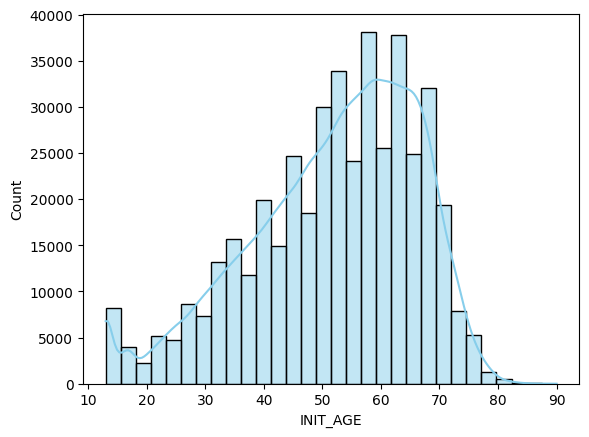

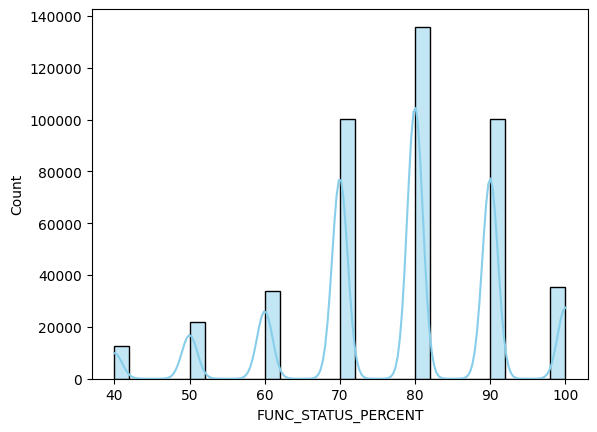

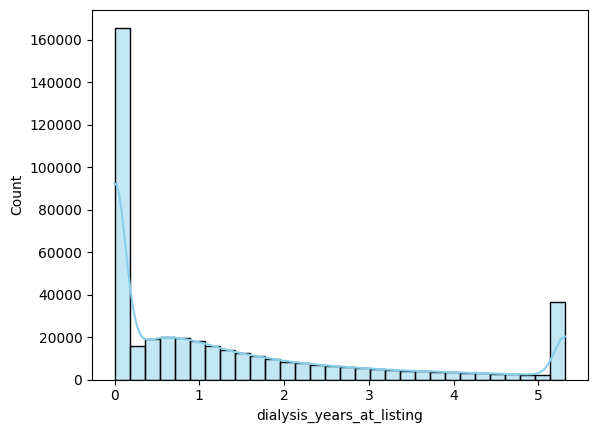

In [ ]:
for col in skewed:
  sns.histplot(data=X, x= col, kde=True, bins=30, color="skyblue")
  plt.show()


Handling the "FUNC_STATUS_PERCENT" column by binning

In [ ]:
#Binning for FUNC_STATUS_PERCENT
# Estimate smooth density
kde = gaussian_kde(X['FUNC_STATUS_PERCENT'])
x_axis = np.linspace(min(X['FUNC_STATUS_PERCENT']), max(X['FUNC_STATUS_PERCENT']), 1000)
density = kde(x_axis)

# Invert density and find the peaks of the inversion
valleys, _ = find_peaks(-density, prominence=0.001)

# Retrieving the actual data values at those valley indices
valley_values = x_axis[valleys]
print(f'The valley points are as follows: {valley_values}')

# Discovering the bins edges for binning
bin_edges = np.sort(np.concatenate([[X['FUNC_STATUS_PERCENT'].min()], valley_values, [X['FUNC_STATUS_PERCENT'].max()]]))
print(f'The bin edges are: {bin_edges}')

#Creating the labels for the bins
FUNC_STATUS_PERCENT_labels = [
    'Severe Limitation',
    'Major Limitation',
    'Moderate-Severe Limitation',
    'Moderate Limitation',
    'Mild-Moderate Limitation',
    'Mostly Independent',
    'Fully Independent'
]
FUNC_STATUS_PERCENT_BINNED = pd.cut(X['FUNC_STATUS_PERCENT'], bins=bin_edges, labels=FUNC_STATUS_PERCENT_labels, include_lowest=True)
print(f'The unique categories for FUNC_STATUS_PERCENT_BINNED {FUNC_STATUS_PERCENT_BINNED.unique()}')

#Ordinal mapping scale of the 7 categories
mapping = {
    'Severe Limitation': 0,
    'Major Limitation': 1,
    'Moderate-Severe Limitation': 2,
    'Moderate Limitation': 3,
    'Mild-Moderate Limitation': 4,
    'Mostly Independent': 5,
    'Fully Independent': 6
}

#Mapping the values
X['FUNC_STATUS_PERCENT_MAPPED'] = FUNC_STATUS_PERCENT_BINNED.map(mapping).astype(float)
print(f'The unique numbers for FUNC_STATUS_PERCENT_MAPPED {X["FUNC_STATUS_PERCENT_MAPPED"].unique()}')

# Correctly drop the original column
if 'FUNC_STATUS_PERCENT' in X.columns:
    X.drop(columns=['FUNC_STATUS_PERCENT'], inplace=True)
    print("Successfully dropped 'FUNC_STATUS_PERCENT' column.")


The valley points are as follows: [44.92492492 54.95495495 64.86486486 74.95495495 85.04504505 95.13513514]
The bin edges are: [ 40.          44.92492492  54.95495495  64.86486486  74.95495495
  85.04504505  95.13513514 100.        ]
The unique categories for FUNC_STATUS_PERCENT_BINNED ['Mild-Moderate Limitation', 'Moderate Limitation', 'Mostly Independent', 'Major Limitation', 'Fully Independent', 'Moderate-Severe Limitation', 'Severe Limitation']
Categories (7, object): ['Severe Limitation' < 'Major Limitation' < 'Moderate-Severe Limitation' <
                         'Moderate Limitation' < 'Mild-Moderate Limitation' < 'Mostly Independent' <
                         'Fully Independent']
The unique numbers for FUNC_STATUS_PERCENT_MAPPED [4. 3. 5. 1. 6. 2. 0.]
Successfully dropped 'FUNC_STATUS_PERCENT' column.


Handling the INIT_AGE by Negative Log Transformation

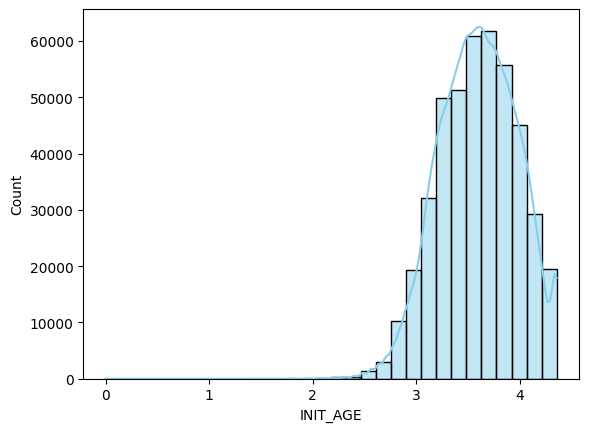

In [ ]:
K = X['INIT_AGE'].max() + 1
X['INIT_AGE'] = np.log(K - X['INIT_AGE'])

sns.histplot(data=X, x= 'INIT_AGE', kde=True, bins=30, color="skyblue")
plt.show()


Handling dialysis_years_at_listing with a positive log transformation

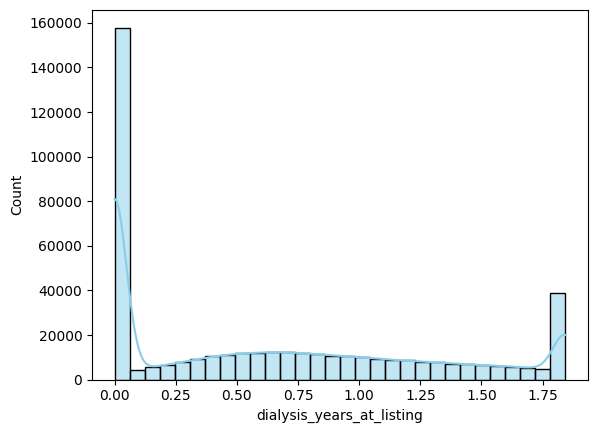

In [ ]:
X['dialysis_years_at_listing'] = np.log1p(X['dialysis_years_at_listing'])

sns.histplot(data=X, x= 'dialysis_years_at_listing', kde=True, bins=30, color="skyblue")
plt.show()

In [ ]:
## Examining the final dataset before processing

print('Checking the head of the X dataset:')
display(X.head())

print('\nChecking the shape of the X dataset:')
print(X.shape)

print('\nChecking the data types in the X dataset:')
display(X.dtypes)

print('\nChecking the statistics of the X dataset:')
display(X.describe())

print('\nChecking the amount of null values in the X dataset:')
display(X.isnull().sum())

Checking the head of the X dataset:


,INIT_AGE,BMI_TCR_CLEAN,dialysis_at_listing,dialysis_years_at_listing,BMI_TCR_MISSING,INIT_CPRA_MISSING,INIT_CPRA_CLEAN_MAPPED,ABO_A,ABO_A1,ABO_A1B,ABO_A2,ABO_A2B,ABO_AB,ABO_B,ABO_O,INIT_STAT_4010,INIT_STAT_4020,INIT_STAT_4050,INIT_STAT_4060,INIT_STAT_4099,A2A2B_STATUS_eligible,A2A2B_STATUS_not_applicable,A2A2B_STATUS_not_eligible,A2A2B_STATUS_unknown,FUNC_STATUS_SCALE_adult_karnofsky,FUNC_STATUS_SCALE_missing,FUNC_STATUS_SCALE_not_applicable,FUNC_STATUS_SCALE_pediatric_lansky,FUNC_STATUS_SCALE_unknown,GENDER_F,GENDER_M,ETHCAT_1,ETHCAT_2,ETHCAT_4,ETHCAT_5,ETHCAT_6,ETHCAT_7,ETHCAT_9,ETHCAT_998,REGION_1,REGION_10,REGION_11,REGION_2,REGION_3,REGION_4,REGION_5,REGION_6,REGION_7,REGION_8,REGION_9,FUNC_STATUS_PERCENT_MAPPED
0,3.637586,31.63,1,1.094497,0,0,0.0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,4.0
1,3.555348,30.04,1,1.251883,0,0,0.0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,3.0
2,3.784190,32.85,0,0.000000,0,0,0.0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,3.0
3,3.401197,20.00,1,0.806586,0,0,0.0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,5.0
4,3.401197,23.30,1,0.727790,0,0,0.0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,3.0



Checking the shape of the X dataset:
(439887, 51)

Checking the data types in the X dataset:


,0
INIT_AGE,float64
BMI_TCR_CLEAN,float64
dialysis_at_listing,int64
dialysis_years_at_listing,float64
BMI_TCR_MISSING,int64
INIT_CPRA_MISSING,int64
INIT_CPRA_CLEAN_MAPPED,float64
ABO_A,int64
ABO_A1,int64
ABO_A1B,int64



Checking the statistics of the X dataset:


,INIT_AGE,BMI_TCR_CLEAN,dialysis_at_listing,dialysis_years_at_listing,BMI_TCR_MISSING,INIT_CPRA_MISSING,INIT_CPRA_CLEAN_MAPPED,ABO_A,ABO_A1,ABO_A1B,ABO_A2,ABO_A2B,ABO_AB,ABO_B,ABO_O,INIT_STAT_4010,INIT_STAT_4020,INIT_STAT_4050,INIT_STAT_4060,INIT_STAT_4099,A2A2B_STATUS_eligible,A2A2B_STATUS_not_applicable,A2A2B_STATUS_not_eligible,A2A2B_STATUS_unknown,FUNC_STATUS_SCALE_adult_karnofsky,FUNC_STATUS_SCALE_missing,FUNC_STATUS_SCALE_not_applicable,FUNC_STATUS_SCALE_pediatric_lansky,FUNC_STATUS_SCALE_unknown,GENDER_F,GENDER_M,ETHCAT_1,ETHCAT_2,ETHCAT_4,ETHCAT_5,ETHCAT_6,ETHCAT_7,ETHCAT_9,ETHCAT_998,REGION_1,REGION_10,REGION_11,REGION_2,REGION_3,REGION_4,REGION_5,REGION_6,REGION_7,REGION_8,REGION_9,FUNC_STATUS_PERCENT_MAPPED
count,439887.000000,439887.000000,439887.000000,439887.000000,439887.00000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000
mean,3.598358,28.798068,0.650533,0.645674,0.00369,0.242926,0.286378,0.316472,0.005010,0.000475,0.000746,0.000161,0.038021,0.149209,0.489905,0.716391,0.000039,0.000432,0.000066,0.283073,0.022067,0.850791,0.054562,0.072580,0.955877,0.000741,0.000239,0.024975,0.018168,0.380000,0.620000,0.412222,0.292489,0.196435,0.074928,0.007982,0.004997,0.008377,0.002571,0.041472,0.065403,0.120292,0.121661,0.139245,0.112813,0.166375,0.027439,0.081623,0.052700,0.070977,3.744009
std,0.373788,5.715551,0.476802,0.640999,0.06063,0.428851,0.746853,0.465100,0.070607,0.021792,0.027296,0.012704,0.191247,0.356295,0.499899,0.450750,0.006217,0.020778,0.008119,0.450492,0.146902,0.356295,0.227123,0.259446,0.205368,0.027213,0.015448,0.156048,0.133560,0.485387,0.485387,0.492235,0.454906,0.397301,0.263276,0.088983,0.070511,0.091143,0.050641,0.199379,0.247236,0.325303,0.326894,0.346202,0.316365,0.372417,0.163359,0.273790,0.223434,0.256787,1.388124
min,0.000000,12.410000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.332205,24.650000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
50%,3.610918,28.510000,1.000000,0.527927,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000
75%,3.871201,32.810000,1.000000,1.140173,0.00000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,


Checking the amount of null values in the X dataset:


,0
INIT_AGE,0
BMI_TCR_CLEAN,0
dialysis_at_listing,0
dialysis_years_at_listing,0
BMI_TCR_MISSING,0
INIT_CPRA_MISSING,0
INIT_CPRA_CLEAN_MAPPED,0
ABO_A,0
ABO_A1,0
ABO_A1B,0


###Summary of Task 6
The skewness of all numerical columns were checked, with the skewness above 0.5 and -0.5 handled. The following features were above the boundaries specified:

1. INIT_AGE had a skew of -0.6391844555659785
2. dialysis_years_at_listing has a skew of 1.2083253188549772
3. FUNC_STATUS_PERCENT has a skew of -0.6186000401328134


INIT_AGE was handled by Negative Log Transformation and dialysis_years_at_listing with a positive log transformation

The continuous numerical features where then converted using the Standard Scaler, becuase it is less senstive to outliers than MinMaxScaler.




### Observation Summary: Functional Status Percent (`FUNC_STATUS_PERCENT`)

#### 1. Nature of the Original Feature
* **Underlying Clinical Meaning**: The functional status score is registered on the Transplant Candidate Registration (TCR) form, measuring a candidate's capacity to complete normal daily physical activities at the time of waitlist registration.
* **The Scale Differences**: The raw field (`FUNC_STAT_TCR`) was split into `FUNC_STATUS_PERCENT` and `FUNC_STATUS_SCALE` because it natively blends two discrete grading systems (Adult Karnofsky Performance Status and Pediatric Lansky Play Performance Scale) along with special/unknown categories. Values represent percent scores ranging from **40% to 100%**, where higher values show stronger independence and lower values signify profound functional limitations.

#### 2. Derivation of Bins & Threshold Detection
* **Valley Detection via Smooth Density Estimation**: Rather than arbitrarily dividing the percentages, a Gaussian Kernel Density Estimate (KDE) was calculated over the continuous range of `FUNC_STATUS_PERCENT` to model the real distribution.
* **Mathematical Bin Boundaries**: By identifying local minima in the density curves, valleys were discovered at key points: **44.92%, 54.95%, 64.86%, 74.95%, 85.05%, and 95.14%**.
* This split the dataset into exactly **7 distinct clinical bins** (8 edges total: minimum 40% up to maximum 100%).

#### 3. Summary of Categories and the Mapping Scale
We mapped the 7 intervals to descriptive categorical labels and assigned them an ordinal numeric scale ($0$ to $6$) indicating the level of functioning:

| Interval Range (%) | Category Label | Ordinal Mapping Score |
| :--- | :--- | :---: |
| **[40.00, 44.92]** | `Severe Limitation` | **0** |
| **(44.92, 54.95]** | `Major Limitation` | **1** |
| **(54.95, 64.86]** | `Moderate-Severe Limitation` | **2** |
| **(64.86, 74.95]** | `Moderate Limitation` | **3** |
| **(74.95, 85.05]** | `Mild-Moderate Limitation` | **4** |
| **(85.05, 95.14]** | `Mostly Independent` | **5** |
| **(95.14, 100.0]** | `Fully Independent` | **6** |

#### 4. Patient Population Insights
* **Most Common States**: The patient population features strong clusters around `Mild-Moderate Limitation` (centered near 80%) and `Mostly Independent` (centered near 90%). This suggests that most patients registered on the kidney transplant waitlist still retain moderate to high self-care capabilities.
* **Preservation of Clinical Saliency**: Binning the variable using physical valley points rather than global mean imputation prevents our model from losing key thresholds of physical decline while smoothing out local random variations within the scores.

### Saving Relevant File changes

In [57]:
# Define the output directory on Google Drive
output_dir = "/content/drive/MyDrive/Healthcare 1C - Fall AI Studio/Healthcare 1C group dataset/processed_output"
os.makedirs(output_dir, exist_ok=True)

# Define individual file paths
x_path = os.path.join(output_dir, "X_processed.csv.gz")
y_path = os.path.join(output_dir, "y_processed.csv.gz")
metadata_path = os.path.join(output_dir, "dataset_metadata.json")

# Check if all files already exist
if os.path.exists(x_path):
    print("Processed dataset files and metadata already exist in Google Drive. Bypassing save operations.")
else:
    print("Saving dataset files...")
    # Save the processed feature matrix (X) and target array (y)
    X.to_csv(x_path, index=True, compression="gzip")
    y.to_frame().to_csv(y_path, index=True, compression="gzip")
    print("Features and targets saved successfully!")

    # Create and save a metadata registry dictionary
    metadata = {
        "num_samples": int(X.shape[0]),
        "num_features": int(X.shape[1]),
        "feature_names": list(X.columns),
        "target_name": "adverse_365",
        "class_distribution": {
            "0": int((y == 0).sum()),
            "1": int((y == 1).sum())
        }
    }

    with open(metadata_path, "w") as f:
        json.dump(metadata, f, indent=4)

    print(f"Metadata summary successfully written to {metadata_path}")
    print("All file exports completed!")

Saving dataset files...
Features and targets saved successfully!
Metadata summary successfully written to /content/drive/MyDrive/Healthcare 1C - Fall AI Studio/Healthcare 1C group dataset/processed_output/dataset_metadata.json
All file exports completed!
